# Evaluation

This notebook evaluates the model chosen in the model selection notebook, a random forest, on the test set. The test set has not been used for any decision so far.

In [1]:
# The notebook is not in the main folder of the project, so the imports need the working directory corrected.
import json
import os

if "working_directory_corrected" not in vars():
    os.chdir("..")
    working_directory_corrected = True

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier

from data.dataset import EPISODES_DIR, build_xy, load_episodes, split_off_test
from data.features import FEATURE_NAMES
from evaluation.evaluation_metrics import EvaluationMetrics
from models.majority_guessing_benchmark import MajorityGuessingBenchmark

## Data and model

The forest is trained on everything except the test set (320 episodes) and then predicts the 80 test episodes once.

In [2]:
episodes = load_episodes()
X, y = build_xy(episodes)
X_rest, X_test, y_rest, y_test = split_off_test(X, y)

# the same split applied to the episode numbers tells which episodes are in the test set
_, test_indices, _, _ = split_off_test(np.arange(len(episodes)), y)

model = RandomForestClassifier(n_estimators=100, random_state=0)
model.fit(X_rest, y_rest)
y_pred = model.predict(X_test)

## Results

In [3]:
benchmark = MajorityGuessingBenchmark()
benchmark.fit(X=X_rest, y=y_rest)
EvaluationMetrics(y_true=y_test, y_pred=benchmark.predict(X=X_test)).print_evaluation_report("Majority Guessing - Test Set")
print()
test_metrics = EvaluationMetrics(y_true=y_test, y_pred=y_pred)
test_metrics.print_evaluation_report("Random Forest - Test Set")

Majority Guessing - Test Set
- accuracy: 0.76
- f1 failure: 0.0  f1 success: 0.87
- macro f1: 0.43
- confusion matrix (rows: true failure, true success):
[[ 0 19]
 [ 0 61]]

Random Forest - Test Set
- accuracy: 0.95
- f1 failure: 0.9  f1 success: 0.97
- macro f1: 0.93
- confusion matrix (rows: true failure, true success):
[[18  1]
 [ 3 58]]


On the test set the forest reaches a macro F1 of 0.93. It finds 18 of the 19 failures and raises 3 false alarms. This is in the range of the validation runs (0.94 ± 0.02), so the model selection did not overfit to the validation data.

Majority guessing stays at 0.43.

## What does the model look at?

A random forest can report how much each feature contributed to its decisions.

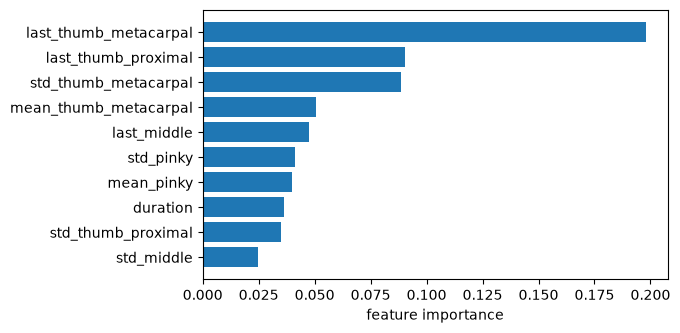

In [4]:
order = np.argsort(model.feature_importances_)[::-1][:10]

plt.figure(figsize=(6, 3.5))
plt.barh([FEATURE_NAMES[i] for i in order][::-1], model.feature_importances_[order][::-1])
plt.xlabel("feature importance")
plt.show()

The most important feature by far is `last_thumb_metacarpal`, the thumb position in the last frame. Most of the other top features also describe the thumb or the fingers. Of the arm joints none is in the top 10, and the episode length matters much less than I expected after the exploration.

## A rule with one feature

If the thumb position at the end is that important, how far does a rule get that only looks at this one value? "The thumb is still closed at the end (above 0.7 rad) → failure".

In [5]:
thumb_at_end = X_test[:, FEATURE_NAMES.index("last_thumb_metacarpal")]
rule_pred = (thumb_at_end < 0.7).astype(int)

rule_metrics = EvaluationMetrics(y_true=y_test, y_pred=rule_pred)
rule_metrics.print_evaluation_report("Thumb Rule - Test Set")

Thumb Rule - Test Set
- accuracy: 0.93
- f1 failure: 0.86  f1 success: 0.95
- macro f1: 0.9
- confusion matrix (rows: true failure, true success):
[[18  1]
 [ 5 56]]


The rule reaches a macro F1 of 0.90 with a single comparison. The forest with its 66 features is only a little better (0.93, that is two fewer false alarms on 80 episodes).

So most of what the forest learned is this: did the robot bring its hand back to the start position at the end or not.

## Error analysis

Which test episodes does the forest get wrong?

In [6]:
for index in test_indices[y_pred != y_test]:
    episode = episodes[index]
    meta = json.loads((EPISODES_DIR / f"{episode.name}.json").read_text())
    predicted = model.predict(X[index : index + 1])[0]
    print(f"{episode.name}: true={int(episode.success)} predicted={predicted}")
    print(f"  duration={episode.timestamp[-1]:.1f}s  timed_out={meta['outcome']['timed_out']}  perturbation={meta['perturbation']['kind']}")
    print(f"  thumb at end={X[index, FEATURE_NAMES.index('last_thumb_metacarpal')]:.2f}")
    for event in meta["policy_info"]["events"]:
        print("  -", event)

episode_117: true=0 predicted=1
  duration=19.3s  timed_out=False  perturbation=drop
  thumb at end=0.06
  - t=7.57 lost the object during transport: open, rise, pick it up again
episode_311: true=1 predicted=0
  duration=14.9s  timed_out=False  perturbation=drop
  thumb at end=1.36
  - t=6.87 lost the object during transport: open, rise, pick it up again
  - t=10.67 grasp attempt 2 failed (rose 0.0 cm): open, rise, try again
  - t=14.33 giving up after 3 attempts
episode_237: true=1 predicted=0
  duration=18.6s  timed_out=False  perturbation=drop
  thumb at end=1.51
  - t=8.13 lost the object during transport: open, rise, pick it up again
  - t=13.60 grasp attempt 2 failed (rose 0.1 cm): open, rise, try again
  - t=18.03 giving up after 3 attempts
episode_195: true=1 predicted=0
  duration=17.0s  timed_out=False  perturbation=drop
  thumb at end=1.51
  - t=7.67 lost the object during transport: open, rise, pick it up again
  - t=10.37 arm blocked during approach: back up and try again

Three of the four errors look the same: the robot lost the object, gave up, and the episode still counts as a success. The object must have ended up in the tray anyway. The forest says "failure" for them, which is what the arm's behaviour looks like.

The fourth error (episode_117) is the opposite: the robot finished its routine normally, but the object is beside the tray. Nothing in the joint data shows that.

How common are these two cases in the whole dataset? The thumb rule from above is used as a stand-in for "the robot finished its routine".

In [7]:
finished = X[:, FEATURE_NAMES.index("last_thumb_metacarpal")] < 0.7

print("robot finished its routine, episode successful:", (finished & (y == 1)).sum())
print("robot finished its routine, episode failed:    ", (finished & (y == 0)).sum())
print("robot did not finish, episode successful:      ", (~finished & (y == 1)).sum())
print("robot did not finish, episode failed:          ", (~finished & (y == 0)).sum())

robot finished its routine, episode successful: 281
robot finished its routine, episode failed:     2
robot did not finish, episode successful:       22
robot did not finish, episode failed:           95


In 376 of 400 episodes "the robot finished its routine" and "the episode was successful" are the same thing. That is what the model learned, and it explains the scores.

The episodes where the two differ are the interesting ones, and there the joint data does not help:
- 22 episodes are successful although the robot did not finish. I checked the JSON files: 15 of them ran into the 20 s limit, in the other 7 the robot gave up and the object was in the tray anyway.
- 2 episodes failed although the robot finished normally. These are the failures the robot does not notice itself, and with only 2 examples a model can not learn anything about them.

## Discussion

The question was whether a model can tell from the joint data alone if an episode succeeded. On this dataset the answer is yes, with a macro F1 of 0.93 on unseen episodes, far above the benchmarks.

But the model does not detect whether the object is in the tray. It detects whether the scripted expert behaved as if it had succeeded: the expert checks the object itself, tries again when it loses it and gives up after three attempts. The model reads this reaction from the hand. That has consequences:

- With a different policy the model will probably not work. A policy that always finishes its routine, no matter what happened to the object, would look successful every time.
- The failures that would be most useful to catch are the ones the robot does not notice itself. There are 2 of them in 400 episodes, and the model misses the one that is in the test set.
- All episodes are simulated. Nothing here was tested on the real robot.

Other limitations:
- The arm features are not mirrored between left and right arm (see data preparation). The model did not use the arm joints much, so this probably did not cost a lot.
- 80 test episodes with 19 failures is a small test set. One episode more or less changes the failure F1 by about 0.03.

## Conclusion

The random forest works on this dataset, but mostly because the expert already knows when it failed. A simple rule on one joint is nearly as good.

To really answer "is the object in the tray" the model needs information about the object. The joint data does not contain that. The next step would be the head camera image of the last frame as input, with the same labels.